In [3]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns
import json

import sys
sys.path.append('../../vision')

import datasets
import training_loop
import losses
import models

if torch.cuda.is_available():
    device = torch.device("cuda:1")
else:
    device = torch.device('cpu')
print(device)

cuda:1


# Labels dataset

In [6]:
dfs = []
for csvfile in sorted(glob.glob('/home/trevor/repos/deep_TEE/labels/cyclic_view_labeling/*.csv')):
    dfs.append(pd.read_csv(csvfile, index_col=False))

view_labels = pd.concat(dfs).reset_index(drop=True)

# currently only use the positive predictions:
view_labels = view_labels.loc[view_labels['Unnamed: 2'] == 'y'].reset_index(drop=True)


/tmp/ipykernel_1226064/3371451809.py:3: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  dfs.append(pd.read_csv(csvfile, index_col=False))
/tmp/ipykernel_1226064/3371451809.py:3: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  dfs.append(pd.read_csv(csvfile, index_col=False))
/tmp/ipykernel_1226064/3371451809.py:3: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  dfs.append(pd.read_csv(csvfile, index_col=False))
/tmp/ipykernel_1226064/3371451809.py:3: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  dfs.append(pd.read_csv(csvfile, index_col=False))
/tmp/ipykernel_1226064/3371451809.py:3: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data

In [7]:
len(view_labels)

3570

In [8]:
view_classes = np.unique(np.array(view_labels['prediction']))
view_classes

views_dir = '../../data/semi-processed/supervised/growing_multiview_training/'
views = sorted([os.path.basename(view) for view in glob.glob(views_dir + '*')])

view_names = [views[index] for index in view_classes]

print(f'{view_classes} : {view_names}')

[ 0  1  2  3  5  8 20 23 24 25] : ['deep_tg_col_a', 'dta_sax', 'dta_sax_arch', 'me_2_ch', 'me_4_ch', 'me_5_ch', 'me_lax_col_mv_av', 'other', 'tg_basal_sax', 'tg_mid_pap_sax']


In [9]:
np.argwhere(view_classes==5)

array([[4]])

In [10]:
class MultiviewDataset(torch.utils.data.Dataset):

    def __init__(self, labels_df, transform=None, duration=32, skip=1):
        self.labels_df = labels_df
        self.transform = transform
        self.duration = duration
        self.skip = skip
        self.view_classes = torch.unique(torch.tensor(view_labels['prediction']))

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):      
        label = torch.argwhere(self.view_classes == int(self.labels_df.iloc[idx]['prediction']))
        label = torch.nn.functional.one_hot(label, num_classes=len(self.view_classes))
        
        data = self.__read_images(self.labels_df.iloc[idx]['clip_path'], self.duration, self.skip)
        
        if self.transform:
            data = self.transform(data)
            
        data = data.permute(1,0,2,3) # reshape to (C,T,H,W)
            
        return {'data':data, 'label':label, 'path':self.labels_df.iloc[idx]['clip_path']}
    
    
    def __read_images(self, path, duration=32, skip=1):
        frame_paths = glob.glob(path+'/*')

        if len(frame_paths) <= duration * skip:
            start = 0
            stop = len(frame_paths)
            pad = (duration * skip - stop) // skip
        else:
            start = np.random.randint(0, len(frame_paths) - duration * skip + 1)
            stop = start + duration * skip
            pad = 0
        frames = []
        for frame in sorted(frame_paths)[start:stop:skip]:
            frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
        for i in range(pad):
            frames.append(torch.zeros_like(frames[-1]))
        frames = torch.stack(frames, dim=0)
        return frames
    
# plt.imshow(train_dataset[0]['data'][:,0].permute(1,2,0))

In [11]:
# train_transforms = datasets.TransformsComposed('train', size=(224,224))
train_transforms = datasets.TransformsComposed('valtest', size=(224,224))
valtest_transforms = datasets.TransformsComposed('valtest', size=(224,224))

In [12]:
# Perform a dataset shuffle prior to selecting train and val sets:
view_labels = view_labels.sample(frac=1, random_state=0).reset_index(drop=True)

In [13]:
train_dataset = MultiviewDataset(view_labels[:3000], transform=train_transforms, duration=16, skip=1)
test_dataset = MultiviewDataset(view_labels[3000:], transform=valtest_transforms, duration=16, skip=1)

In [36]:
class SimpleLoss:
    def __init__(self,):
        self.crossentropy = torch.nn.CrossEntropyLoss()
        self.output_activation = torch.nn.Softmax(dim=1)

    def __call__(self, net, data, label):
        x = data
        y = net(x).squeeze()
        y = self.output_activation(y)
        label = label.squeeze()
        assert y.shape == label.shape, "mismatched dimensions in model output"
        loss = self.crossentropy(y, label)
        return loss
    
loss_fn = SimpleLoss()

In [37]:
model = models.fetch_s3d_model(
    num_classes = len(view_classes),
    dropout = 0.2,
).to(device)

In [38]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0,)

In [39]:
import torch
import numpy as np
import os
import time
import copy
import json
import pickle
import datasets
import matplotlib.pyplot as plt

def collate_fn(batch):
  return {
      'data': torch.stack([x['data'] for x in batch], dim=0),
      'label': torch.stack([x['label'] for x in batch], dim=0),
}

def simple_training_loop(
    run_dir             = '.',      # Output directory.
    dataset             = None,     # Training dataset
    validation_dataset  = None,     # Validation dataset
    network             = None,     # Options for model and preconditioning.
    loss                = None,     # Options for loss function.
    optimizer           = None,     # Options for optimizer.
    seed                = 0,        # Global random seed.
    batch_size          = 32,       # Total batch size for one training iteration.
    num_workers         = 8,        # Number of data loading workers.
    total_kimg          = 200000,   # Training duration, measured in thousands of training images.
    device              = torch.device('cuda'),
    kimg_per_tick       = 100,      # How often to log training and validation stats.
    kimg_per_save       = 1000,     # How often to save the training state.
    val_length          = 100,       # How many data parcels to run validation on (more takes longer)
):
    # Initialize.
    start_time = time.time()
    if os.path.isdir(run_dir):
        # raise RuntimeError(f'Output directory "{run_dir}" already exists')
        os.makedirs(run_dir, exist_ok=True)
    else:
        os.makedirs(run_dir, exist_ok=True)

    # Load dataset.
    print('Loading dataset...')

    dataset_sampler = iter(datasets.InfiniteSampler(dataset=dataset, rank=0, num_replicas=1, shuffle=True, seed=seed, window_size=0.5))
    dataset_iterator = iter(torch.utils.data.DataLoader(dataset=dataset, batch_size=batch_size, num_workers=num_workers, sampler=dataset_sampler, collate_fn=collate_fn))
    if validation_dataset:
        val_dataset = validation_dataset
        val_dataset_sampler = iter(datasets.InfiniteSampler(dataset=val_dataset, rank=0, num_replicas=1, shuffle=True, seed=seed, window_size=0.5))
        val_dataset_iterator = iter(torch.utils.data.DataLoader(dataset=val_dataset, batch_size=batch_size, num_workers=1, sampler=val_dataset_sampler, collate_fn=collate_fn))

    # Construct network.
    print('Constructing network...')
    net = network
    net.train().requires_grad_(True).to(device)

    # Setup optimizer.
    print('Setting up optimizer...')
    loss_fn = loss
    optimizer = optimizer
    
    # Setup logs.
    print('Setting up logs...')
    running_loss = []
    training_stats = dict(
        tick = [],
        tick_start_time = [],
        tick_runtime = [],
        loss = [],
        std = [],
        valloss = [],
        valstd = [],
    )

    # Train.
    print(f'Training for {total_kimg} kimg...')
    print()
    cur_nimg = 0
    cur_tick = 0
    cur_save = 1
    tick_start_nimg = cur_nimg
    tick_start_time = time.time()
    # dist.update_progress(cur_nimg // 1000, total_kimg)
    
    while True:
        
        # Accumulate gradients.
        optimizer.zero_grad(set_to_none=True)
        parcel = next(dataset_iterator)
        data = parcel['data']
        label = parcel['label']
        data = data.to(device).to(torch.float32)
        label = label.to(device).to(torch.float32)
        loss = loss_fn(net=net, data=data, label=label)
        running_loss.append(loss)
        loss.sum().backward()
        
        
        # print(f'data : {data.shape}')
        # print(f'label : {label}')
        # print(f'loss : {loss}')
        # print(f'image : {parcel["acc"]}')
        # if cur_nimg % 100 == 0:
        #     plt.imshow(data[0,:,0,:,:].permute(1,2,0).cpu())

        # Update weights.
        for param in net.parameters():
            if param.grad is not None:
                torch.nan_to_num(param.grad, nan=0, posinf=1e5, neginf=-1e5, out=param.grad)
        optimizer.step()

        # Perform maintenance tasks once per tick.
        cur_tick += 1
        cur_nimg += batch_size
        done = (cur_nimg >= total_kimg * 1000)
        if (not done) and (cur_tick != 0) and (cur_nimg < tick_start_nimg + kimg_per_tick * 1000):
            continue
        
        # Save full dump of the training state.
        if (not done) and (cur_tick != 0) and (cur_nimg > (cur_save) * kimg_per_save * 1000):
            cur_save += 1
            torch.save(dict(net=net, optimizer_state=optimizer.state_dict()), os.path.join(run_dir, f'training-state-{cur_nimg//1000:06d}.pt'))
            print(f'saved to training-state-{cur_nimg//1000:06d}.pt')
        
        # Validation
        if validation_dataset:
            model.eval()
            with torch.no_grad():
                val_loss = []
                for idx in range(min(val_length, len(val_dataset))):
                    parcel = next(val_dataset_iterator)
                    data = parcel['data']
                    label = parcel['label']
                    data = data.to(device).to(torch.float32)
                    label = label.to(device).to(torch.float32)
                    loss = loss_fn(net=net, data=data, label=label)
                    val_loss.append(loss)
                training_stats['valloss'].append(torch.mean(torch.stack(val_loss)).item())
                training_stats['valstd'].append(torch.std(torch.stack(val_loss)).item())
            model.train()
                
        # Update logs.
        training_stats['tick'].append(cur_tick)
        training_stats['tick_start_time'].append(tick_start_time)
        training_stats['tick_runtime'].append(time.time() - tick_start_time)
        training_stats['loss'].append(torch.mean(torch.stack(running_loss)).item())
        training_stats['std'].append(torch.std(torch.stack(running_loss)).item())
        json.dump(training_stats, open(os.path.join(run_dir, 'log.json'), 'wt'))
        running_loss = []
        if validation_dataset:
            print(f"tick {cur_tick}, loss {training_stats['loss'][-1]:.4f}, std {training_stats['std'][-1]:.4f}, valloss {training_stats['valloss'][-1]:.4f}, valstd {training_stats['valstd'][-1]:.4f}, time {training_stats['tick_runtime'][-1]:.2f} sec")
        else:
            print(f"tick {cur_tick}, loss {training_stats['loss'][-1]:.4f}, std {training_stats['std'][-1]:.4f}, time {training_stats['tick_runtime'][-1]:.2f} sec")

        # Update state.
        tick_start_nimg = cur_nimg
        tick_start_time = time.time()
        if done:
            break

    # Done.
    print()
    print('Exiting...')

#----------------------------------------------------------------------------

In [40]:
simple_training_loop(
    run_dir             = '../../experiments/multiview_classification_s3d_224_16_1_test1',  # Output directory.
    dataset             = train_dataset,                # Options for training set.
    validation_dataset  = test_dataset,                 # Options for training set.
    network             = model,                        # Options for model and preconditioning.
    loss                = loss_fn,                      # Options for loss function.
    optimizer           = optimizer,                    # Options for optimizer.
    seed                = 0,                            # Global random seed.
    batch_size          = 32,                           # Total batch size for one training iteration.
    num_workers         = 4,                            # Number of data loading workers.
    total_kimg          = 1000,                          # Training duration, measured in thousands of training images.
    kimg_per_tick       = 25,                           # How often to log training and validation stats.
    kimg_per_save       = 25,                           # How often to save the training state.
    device              = torch.device('cuda'),
    val_length          = 1000,       # How many data parcels to run validation on (more takes longer)
)

Loading dataset...
Constructing network...
Setting up optimizer...
Setting up logs...
Training for 1000 kimg...

saved to training-state-000025.pt
tick 782, loss 1.7794, std 0.1397, valloss 2.3219, valstd 0.0326, time 848.49 sec
saved to training-state-000050.pt
tick 1564, loss 1.6477, std 0.0621, valloss 2.1992, valstd 0.0699, time 843.94 sec
saved to training-state-000075.pt
tick 2346, loss 1.6108, std 0.0606, valloss 2.1970, valstd 0.0752, time 846.92 sec
saved to training-state-000100.pt
tick 3128, loss 1.5843, std 0.0533, valloss 2.1982, valstd 0.0750, time 847.79 sec
saved to training-state-000125.pt
tick 3910, loss 1.5709, std 0.0530, valloss 2.2571, valstd 0.0603, time 847.36 sec


KeyboardInterrupt: 

In [34]:
# log = json.load(open('../../experiments/multiview_classification_s3d_224_16_1_1/log.json', 'r'))
log = json.load(open('../../experiments/multiview_classification_s3d_224_16_1_test1/log.json', 'r'))

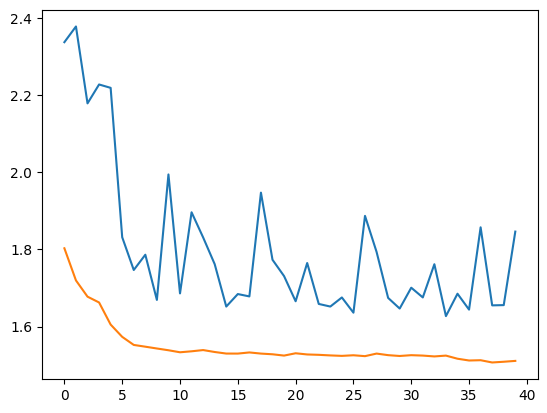

In [35]:
plt.plot(log['valloss'])
plt.plot(log['loss'])

In [24]:
# model = torch.load('/home/trevor/repos/deep_TEE/experiments/multiview_classification_s3d_224_16_1_1/training-state-000400.pt')['net'].eval()
model = torch.load('/home/trevor/repos/deep_TEE/experiments/multiview_classification_s3d_224_16_1_test1/training-state-000800.pt')['net'].to(device).eval()

In [25]:
labels = []
predictions = []
outputs = []

for idx in tqdm.tqdm(range(len(test_dataset))):
    data = test_dataset[idx]['data'].unsqueeze(0).to(device)
    label = test_dataset[idx]['label'].unsqueeze(0).to(device)
    output = model(data)
    predictions.append(torch.nn.functional.softmax(output.cpu().detach(), dim=1).squeeze().numpy())
    labels.append(torch.argmax(label).item())
    outputs.append(torch.argmax(output).item())
    # print(f'prediction : {output.argmax()}')
    # print(f'label : {label.argmax()}')
    # print(f'view : {view_names[label.argmax()]}')

100%|██████████| 570/570 [00:23<00:00, 24.61it/s]


In [26]:
view_classes

array([ 0,  1,  2,  3,  5,  8, 20, 23, 24, 25])

In [27]:
view_names

['deep_tg_col_a',
 'dta_sax',
 'dta_sax_arch',
 'me_2_ch',
 'me_4_ch',
 'me_5_ch',
 'me_lax_col_mv_av',
 'other',
 'tg_basal_sax',
 'tg_mid_pap_sax']

In [28]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import top_k_accuracy_score
from sklearn.metrics import auc, roc_curve, confusion_matrix, ConfusionMatrixDisplay

In [29]:
import itertools

def plot_confusion_matrix(cm, classes, cm2, 
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm2[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    # plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Normalized confusion matrix
[[0.83333333 0.         0.         0.         0.         0.
  0.16666667 0.         0.         0.        ]
 [0.         0.52439024 0.         0.01829268 0.44512195 0.
  0.         0.         0.         0.01219512]
 [0.         1.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         1.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.0931677  0.         0.01242236 0.86335404 0.
  0.         0.         0.         0.0310559 ]
 [0.         0.29411765 0.         0.         0.64705882 0.
  0.         0.         0.         0.05882353]
 [0.         0.         0.         0.         0.         0.
  1.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         1.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         1.        ]
 [0.     

<Figure size 640x480 with 0 Axes>

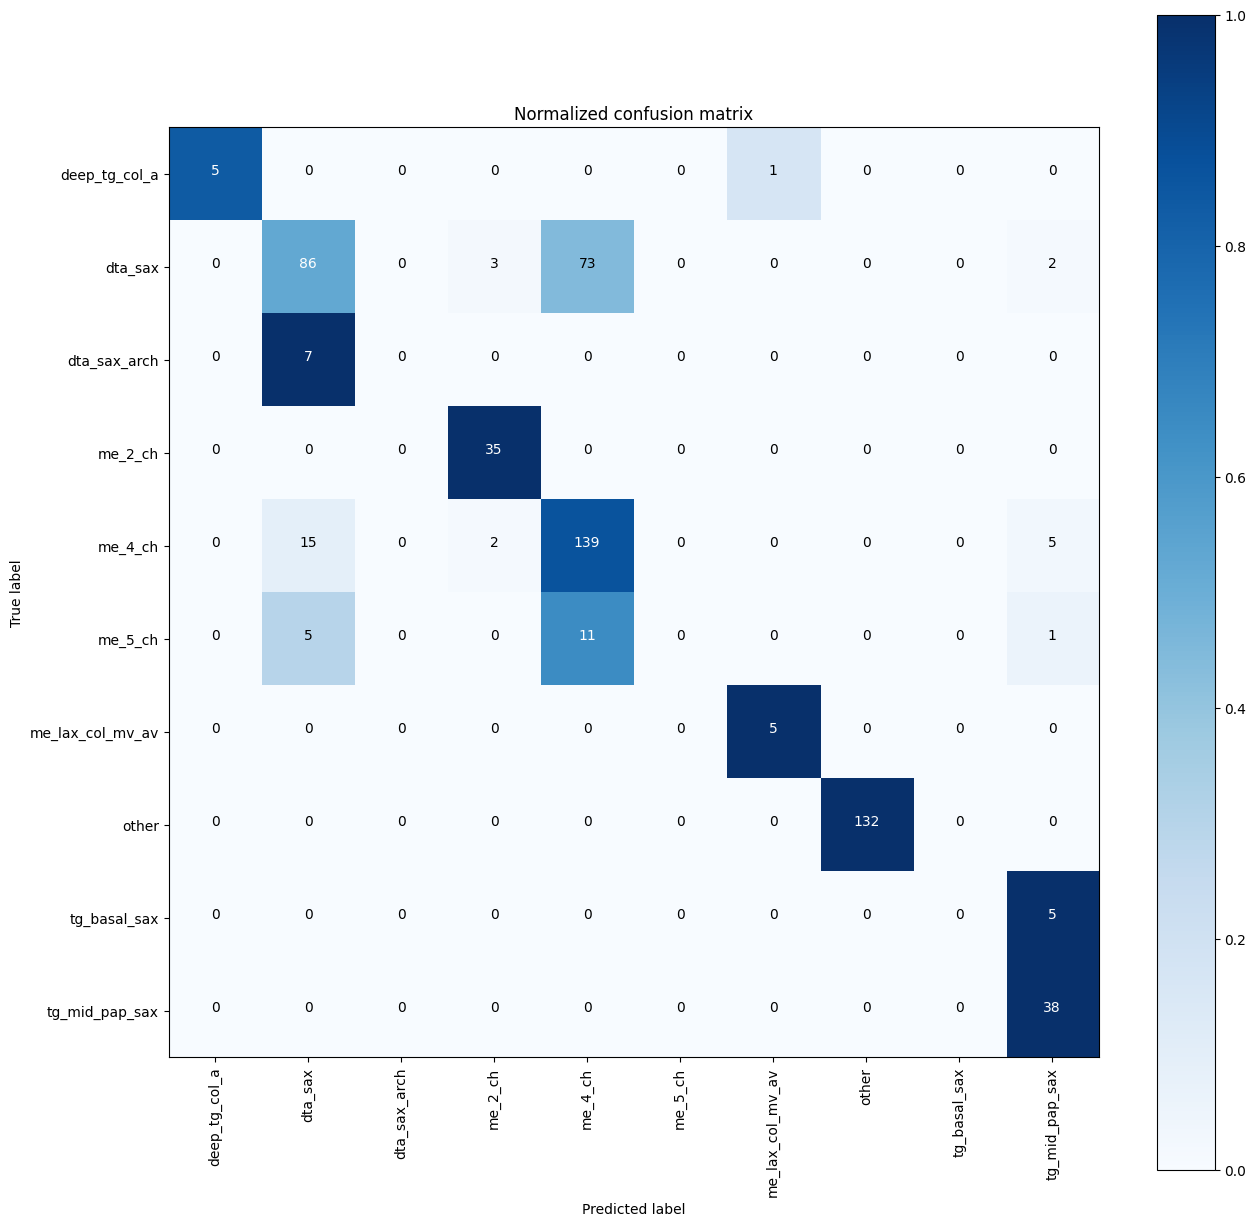

In [30]:
# Compute confusion matrix
cm = confusion_matrix(labels, outputs, normalize='true')
cm2 = confusion_matrix(labels, outputs)

# Plot normalized confusion matrix
plt.figure()
plt.figure(figsize = (15, 15))
plot_confusion_matrix(cm=cm, classes=view_names, cm2=cm2, normalize=True,
                      title='Normalized confusion matrix')



plt.show()

In [31]:
# accuracy: (tp + tn) / (p + n)
accuracy = accuracy_score(labels, outputs)
print('Accuracy: %f' % accuracy)
# precision tp / (tp + fp)
precision = precision_score(labels, outputs, average='weighted')
print('Precision: %f' % precision)
# recall: tp / (tp + fn)
recall = recall_score(labels, outputs, average='weighted')
print('Recall: %f' % recall)
# f1: 2 tp / (2 tp + fp + fn)
f1 = f1_score(labels, outputs, average='weighted')
print('F1 score: %f' % f1)
 
# kappa
kappa = cohen_kappa_score(labels, outputs)
print('Cohens kappa: %f' % kappa)

# ROC AUC
auc = roc_auc_score(labels, predictions, average='weighted', multi_class='ovr')
print('ROC AUC: %f' % auc)

Accuracy: 0.771930
Precision: 0.747849
Recall: 0.771930
F1 score: 0.746504
Cohens kappa: 0.703176
ROC AUC: 0.923146


/home/trevor/miniconda3/envs/view_classification/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


# Checking the training set

0  0 : /data/deep_tee/semi-processed/unsupervised/train/32109114/1.2.840.113663.1500.1.458631247.3.3.20190726.145151.856.dcm
0  1 : /data/deep_tee/semi-processed/unsupervised/train/35635299/1.2.840.113663.1500.1.367404672.3.2.20210606.135412.406.dcm
0  2 : /data/deep_tee/semi-processed/unsupervised/train/31316802/1.2.840.113663.1500.1.458671065.3.83.20190301.110309.305.dcm
0  3 : /data/deep_tee/semi-processed/unsupervised/train/31378949/1.2.840.113663.1500.1.415189332.3.23.20190313.83056.341.dcm
0  4 : /data/deep_tee/semi-processed/unsupervised/train/40694102/1.2.840.113663.1500.1.464794778.3.67.20211229.84328.546.dcm
0  5 : /data/deep_tee/semi-processed/unsupervised/train/31410169/1.2.840.113663.1500.1.423189418.3.10.20190319.84158.359.dcm
0  6 : /data/deep_tee/semi-processed/unsupervised/train/41930231/1.2.840.113663.1500.1.464722284.3.73.20220214.115330.910.dcm
0  7 : /data/deep_tee/semi-processed/unsupervised/train/43725130/1.2.840.113663.1500.1.458614702.3.4.20220503.112859.466.dc

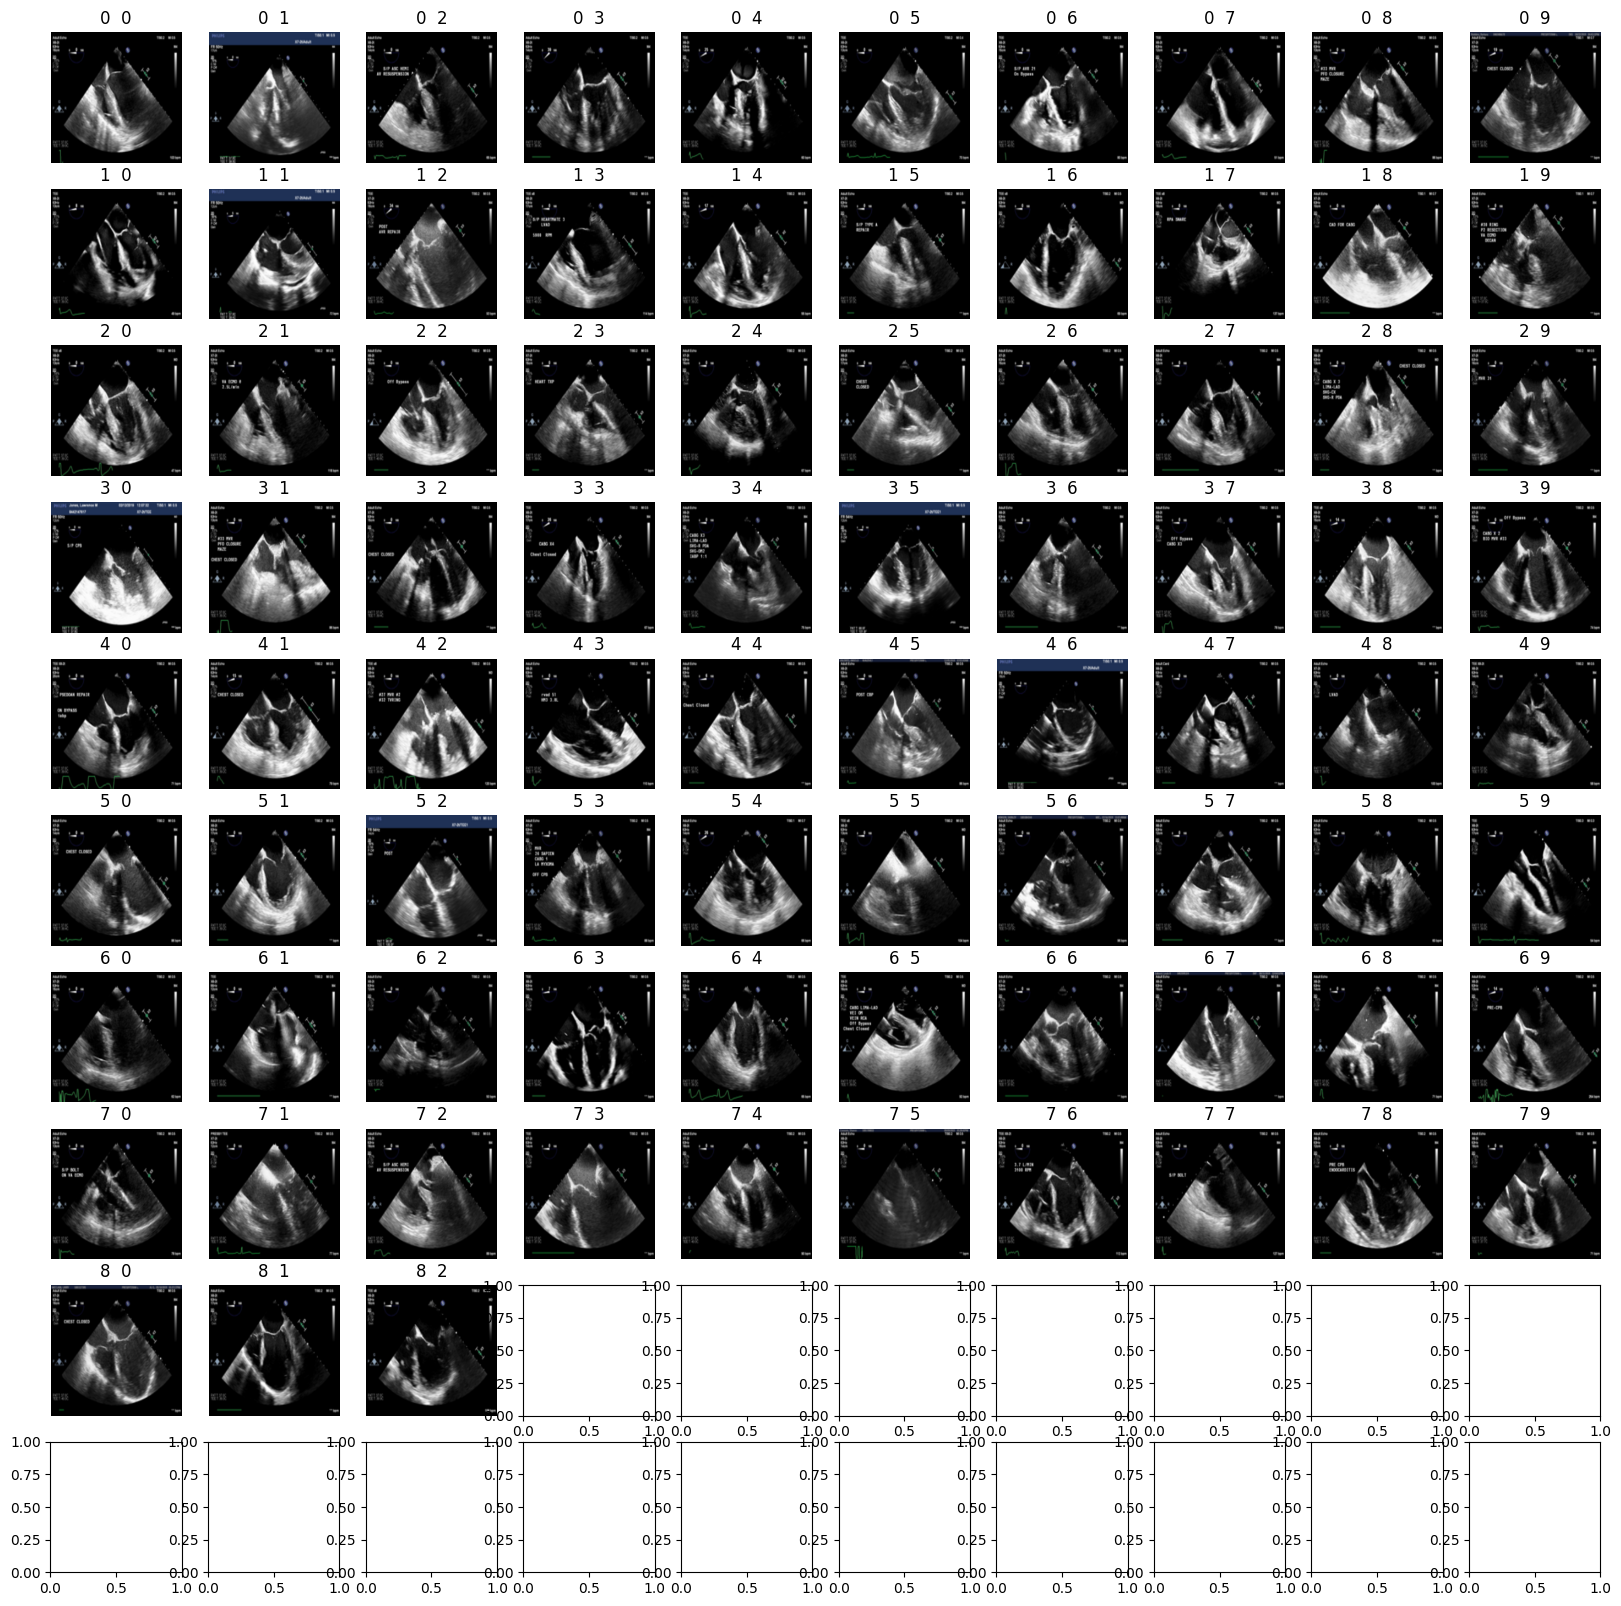

In [ ]:
fig, ax = plt.subplots(10,10,figsize=(20,20))

count = 0
for i in range(200,400):
    if torch.argmax(train_dataset[i]['label']).item() == 4:
        ax[count//10,count%10].imshow(train_dataset[i]['data'][:,0].permute(1,2,0))
        ax[count//10,count%10].axis('off')
        ax[count//10,count%10].set_title(f'{count//10}  {count%10}')
        print(f'{count//10}  {count%10} : {train_dataset[i]["path"]}')
        count += 1
    if count == 100:
        break
    
        